<a href="https://colab.research.google.com/github/rachmadnanda/MachineLearning2026/blob/main/JS5_244107020095_RACHMAD_FEBRIANANDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PRAKTIKUM 1

In [ ]:
!pip install hdbscan

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.cluster import DBSCAN
from sklearn.datasets import make_blobs
import hdbscan

In [ ]:
def plot(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))
    labels = labels if labels is not None else np.ones(X.shape[0])
    probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])
    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    proba_map = {idx: probabilities[idx] for idx in range(len(labels))}

    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]  # warna hitam untuk noise
        class_index = (labels == k).nonzero()[0]
        for ci in class_index:
            ax.plot(
                X[ci, 0],
                X[ci, 1],
                "x" if k == -1 else "o",
                markerfacecolor=tuple(col),
                markeredgecolor="k",
                markersize=4 if k == -1 else 1 + 5 * proba_map[ci],
            )
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    preamble = "True" if ground_truth else "Estimated"
    title = f"{preamble} number of clusters: {n_clusters_}"
    if parameters is not None:
        parameters_str = ", ".join(f"{k}={v}" for k, v in parameters.items())
        title += f" | {parameters_str}"
    ax.set_title(title)
    plt.tight_layout()

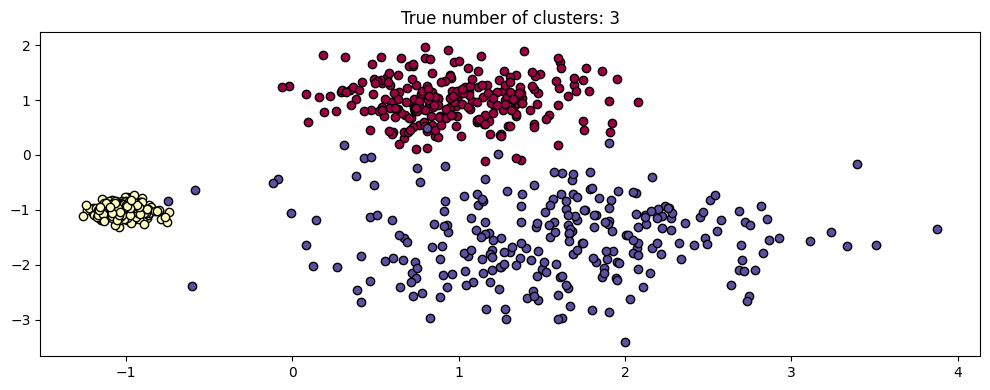

In [ ]:
centers = [[1, 1], [-1, -1], [1.5, -1.5]]
X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=[0.4, 0.1, 0.75], random_state=0
)

plot(X, labels=labels_true, ground_truth=True)
plt.show()

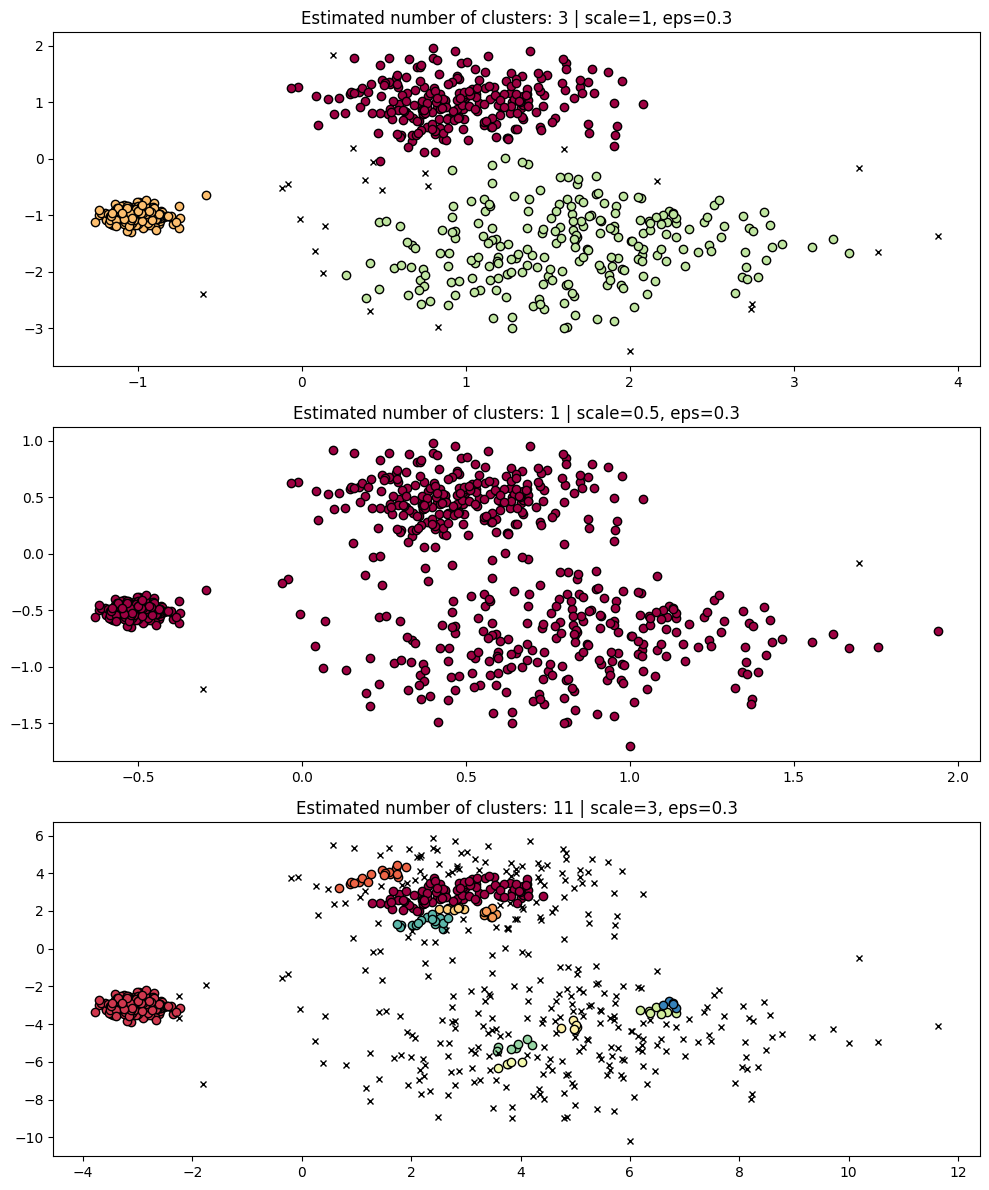

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
dbs = DBSCAN(eps=0.3)
for idx, scale in enumerate([1, 0.5, 3]):
    dbs.fit(X * scale)
    plot(X * scale, dbs.labels_, parameters={"scale": scale, "eps": 0.3}, ax=axes[idx])
plt.show()

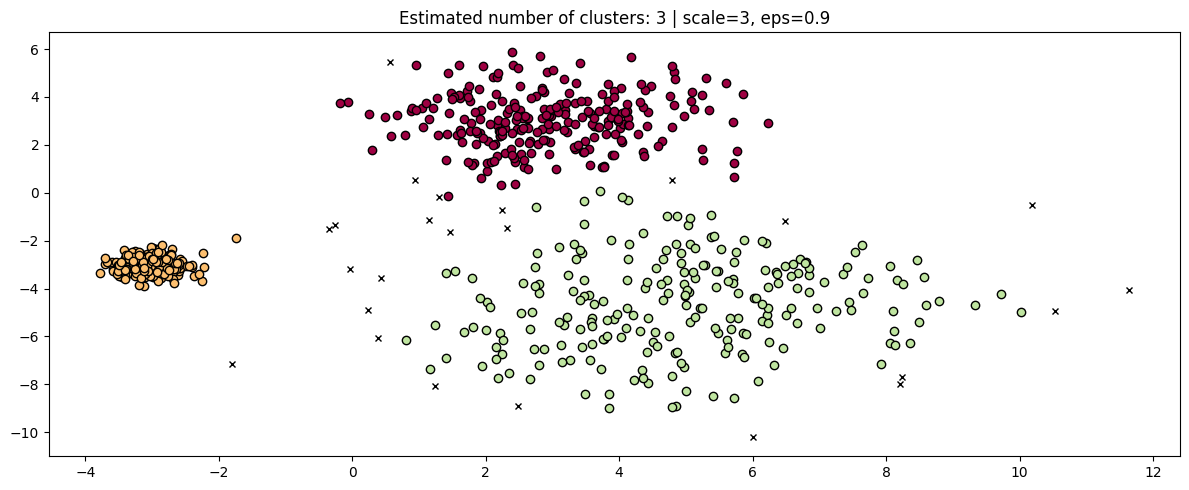

In [ ]:
fig, axis = plt.subplots(1, 1, figsize=(12, 5))
dbs = DBSCAN(eps=0.9).fit(3 * X)
plot(3 * X, dbs.labels_, parameters={"scale": 3, "eps": 0.9}, ax=axis)
plt.show()

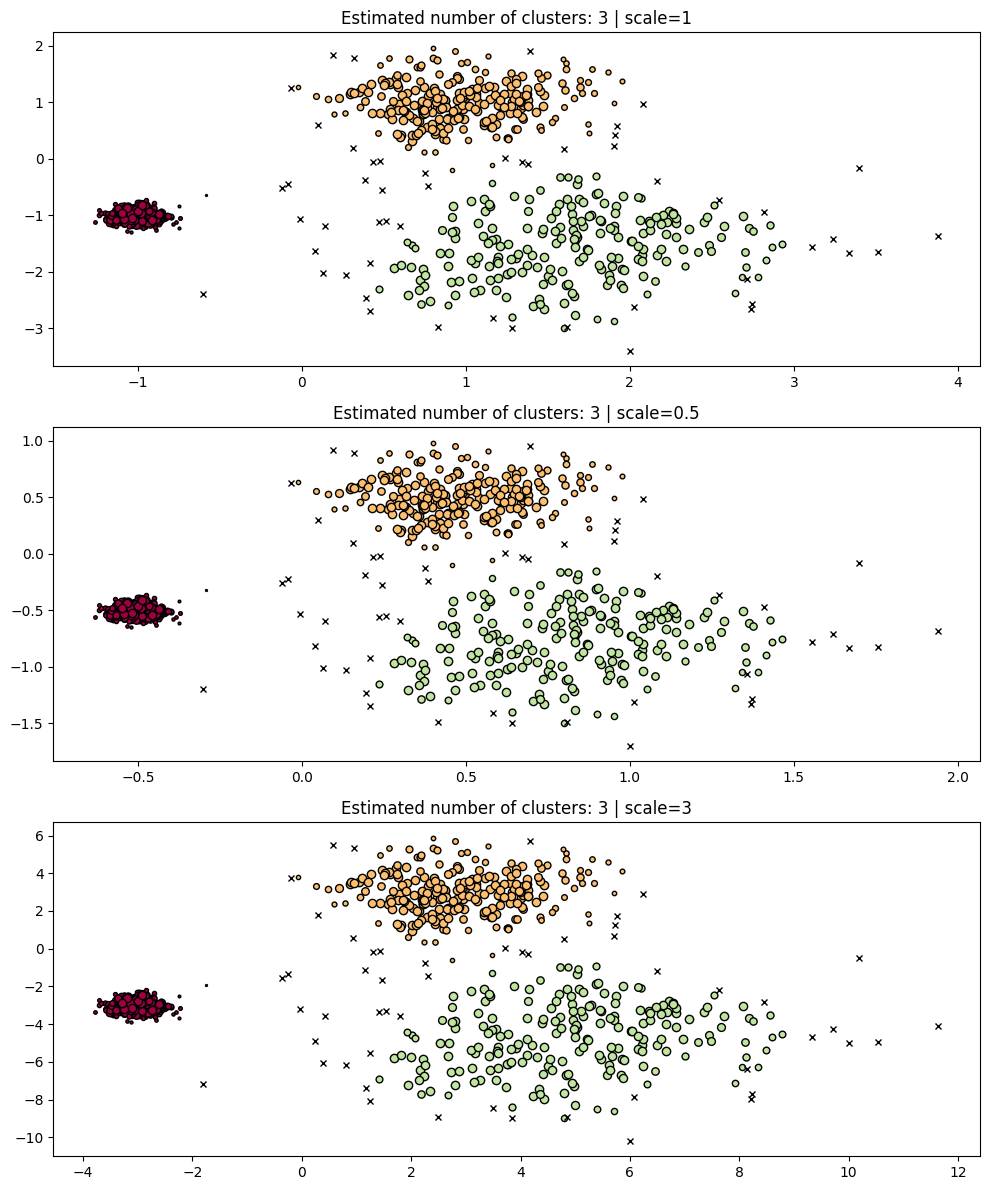

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
hdb = hdbscan.HDBSCAN()
for idx, scale in enumerate([1, 0.5, 3]):
    hdb.fit(X * scale)
    plot(X * scale, hdb.labels_, hdb.probabilities_, ax=axes[idx], parameters={"scale": scale})
plt.show()

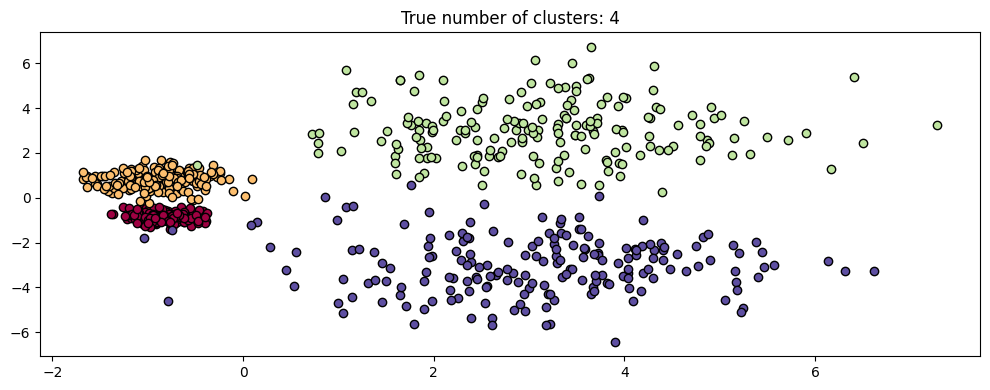

In [ ]:
centers = [[-0.85, -0.85], [-0.85, 0.85], [3, 3], [3, -3]]
X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=[0.2, 0.35, 1.35, 1.35], random_state=0
)
plot(X, labels=labels_true, ground_truth=True)
plt.show()

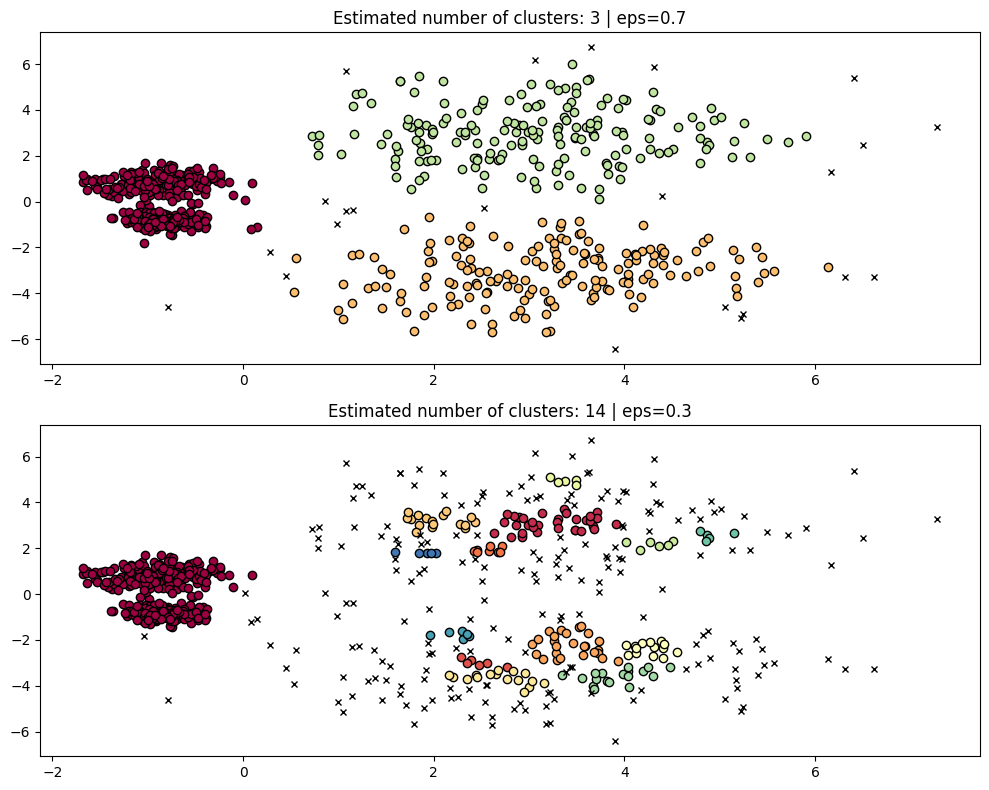

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
params = {"eps": 0.7}
dbs = DBSCAN(**params).fit(X)
plot(X, dbs.labels_, parameters=params, ax=axes[0])

params = {"eps": 0.3}
dbs = DBSCAN(**params).fit(X)
plot(X, dbs.labels_, parameters=params, ax=axes[1])
plt.show()

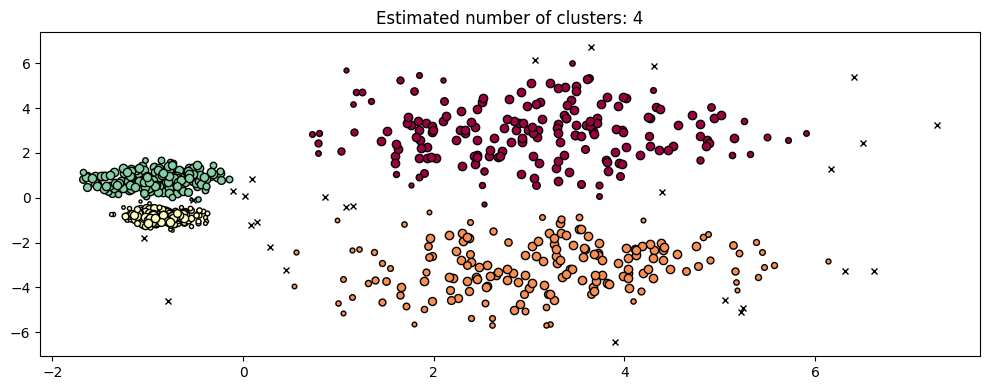

In [ ]:
hdb = hdbscan.HDBSCAN().fit(X)
plot(X, hdb.labels_, hdb.probabilities_)
plt.show()

## PRAKTIKUM 2

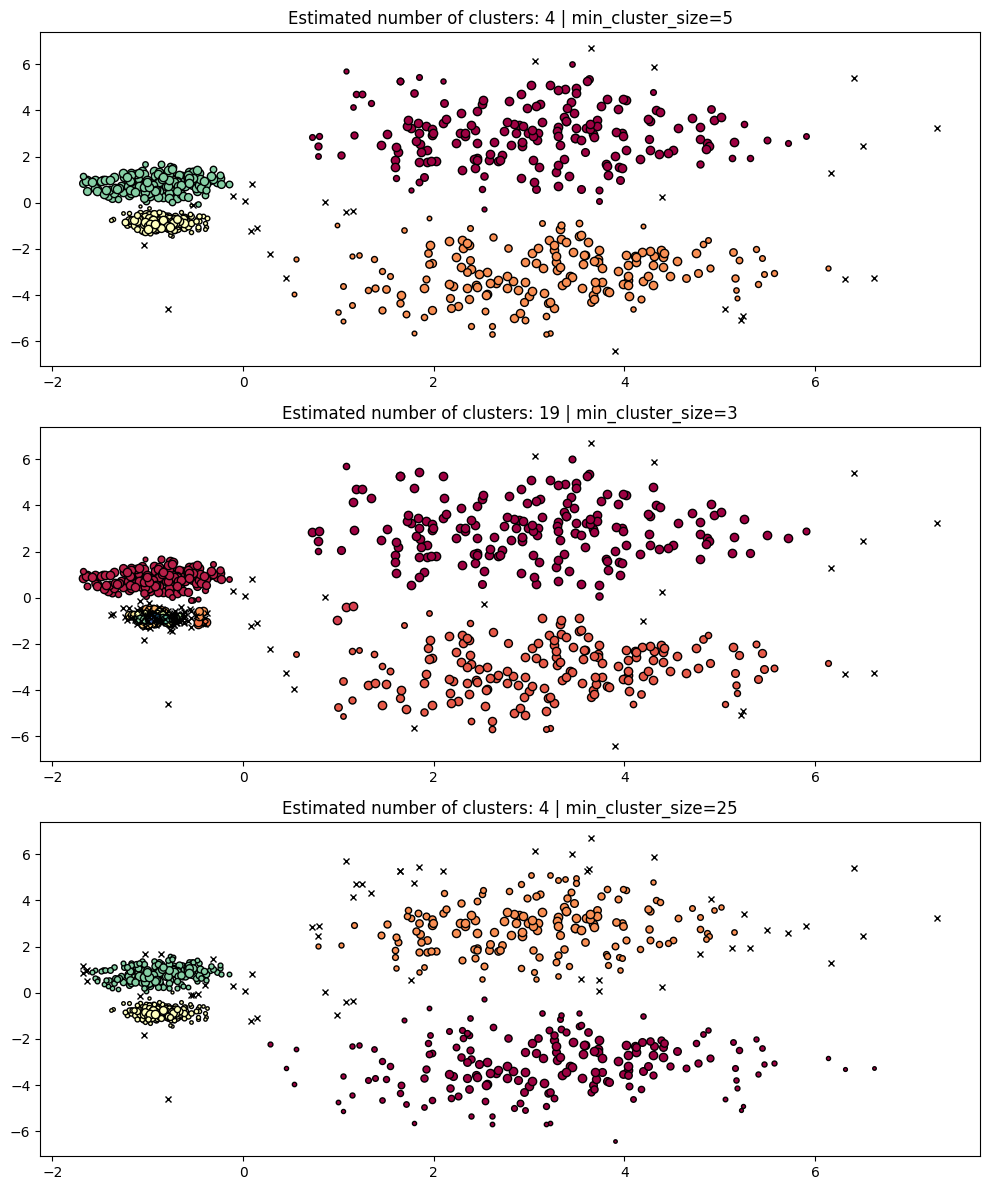

In [ ]:
PARAM = ({"min_cluster_size": 5}, {"min_cluster_size": 3}, {"min_cluster_size": 25})
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    hdb = hdbscan.HDBSCAN(**param).fit(X)
    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])
plt.show()

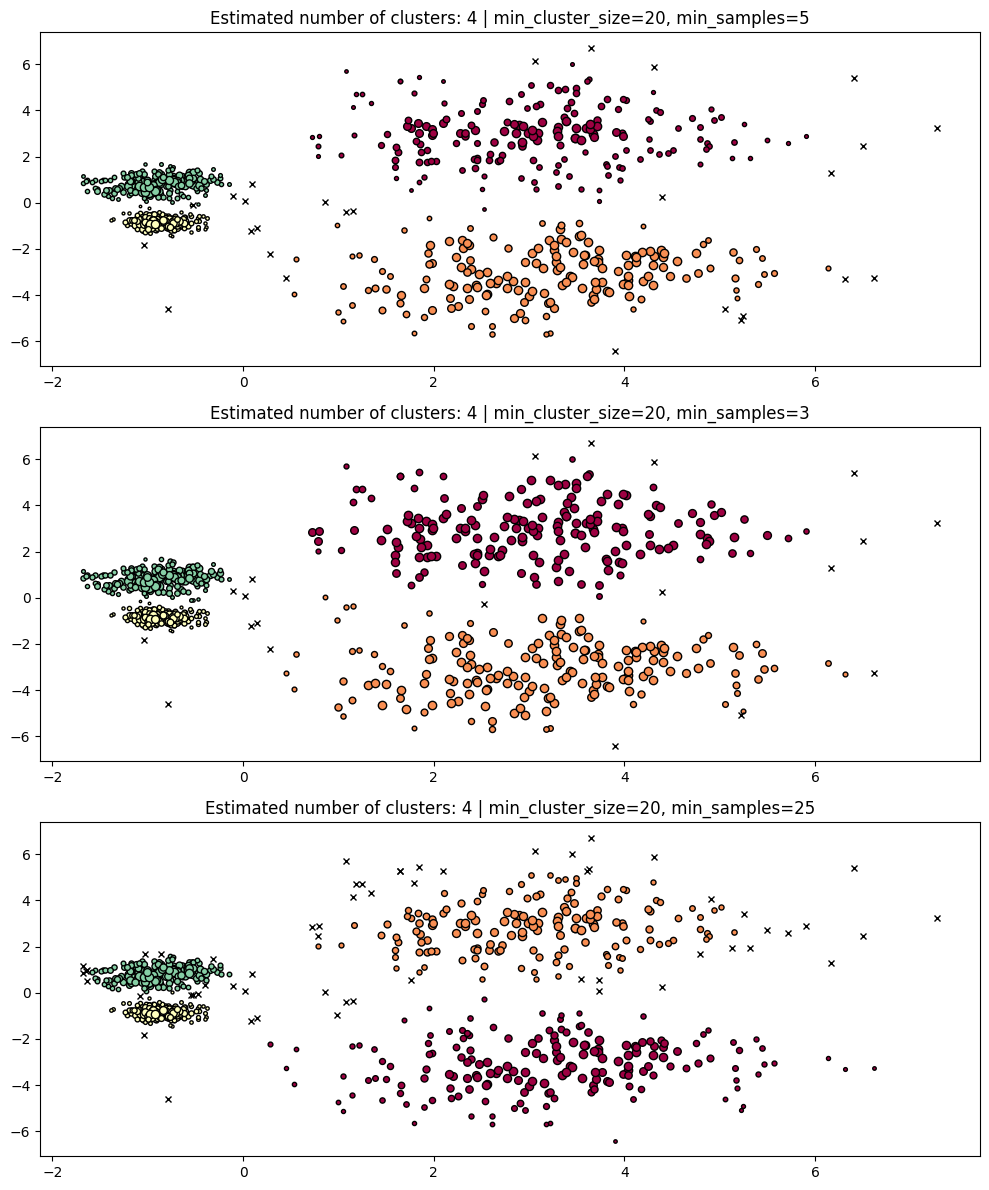

In [ ]:
PARAM = (
    {"min_cluster_size": 20, "min_samples": 5},
    {"min_cluster_size": 20, "min_samples": 3},
    {"min_cluster_size": 20, "min_samples": 25},
)
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    hdb = hdbscan.HDBSCAN(**param).fit(X)
    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])
plt.show()

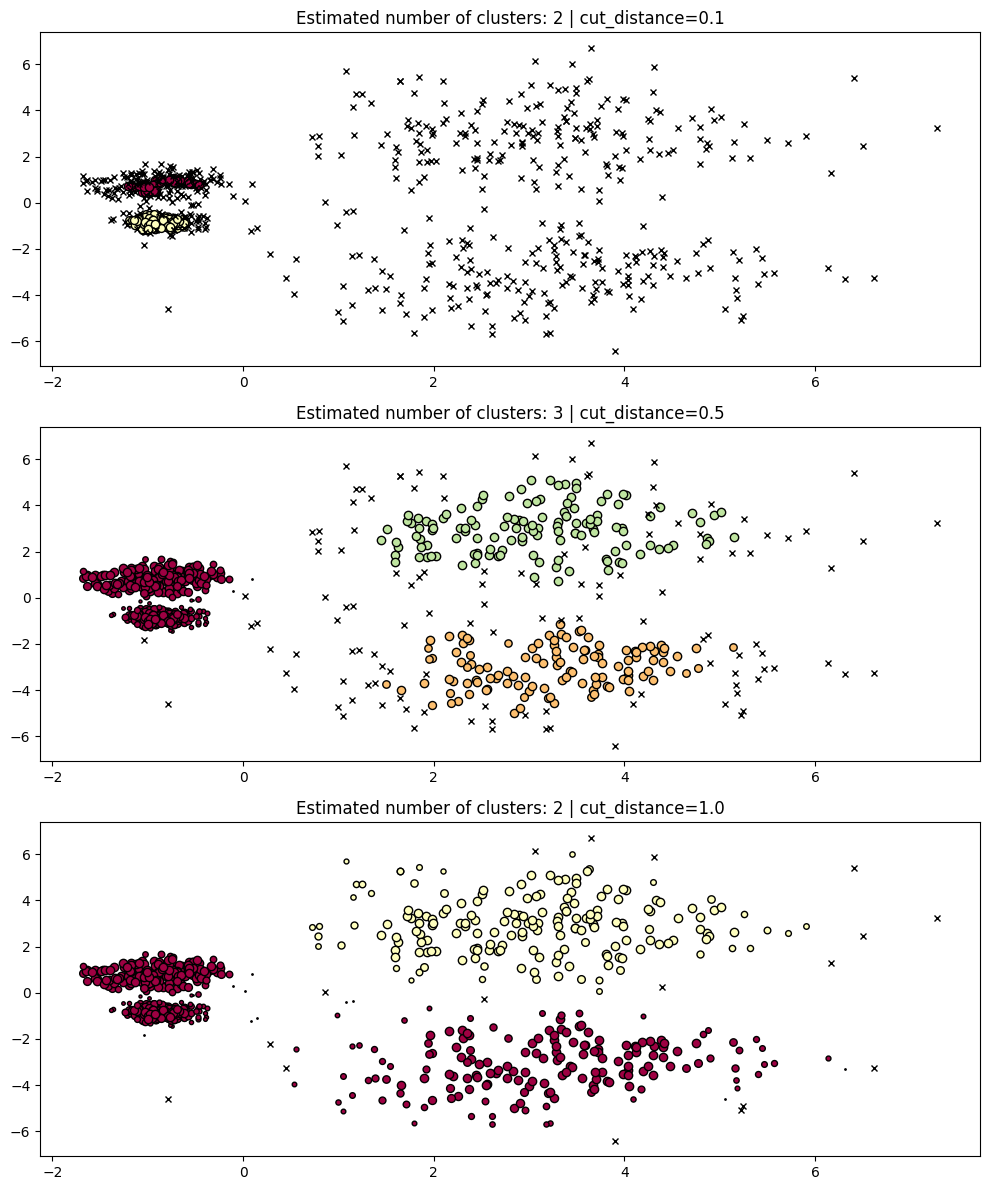

In [ ]:
PARAM = (
    {"cut_distance": 0.1},
    {"cut_distance": 0.5},
    {"cut_distance": 1.0},
)
hdb = hdbscan.HDBSCAN().fit(X)
fig, axes = plt.subplots(len(PARAM), 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    labels = hdb.dbscan_clustering(**param)
    plot(X, labels, hdb.probabilities_, param, ax=axes[i])
plt.show()

In [ ]:
from sklearn.metrics import silhouette_score

# Menghitung Silhouette Score untuk hasil clustering HDBSCAN
sil_score = silhouette_score(X, hdb.labels_)
print(f"Silhouette Score: {sil_score}")

Silhouette Score: 0.5743816709862986


In [ ]:
from sklearn.metrics import davies_bouldin_score

# Menghitung Davies-Bouldin Index untuk hasil clustering HDBSCAN
dbi_score = davies_bouldin_score(X, hdb.labels_)
print(f"Davies-Bouldin Index: {dbi_score}")

Davies-Bouldin Index: 1.6436030674842066


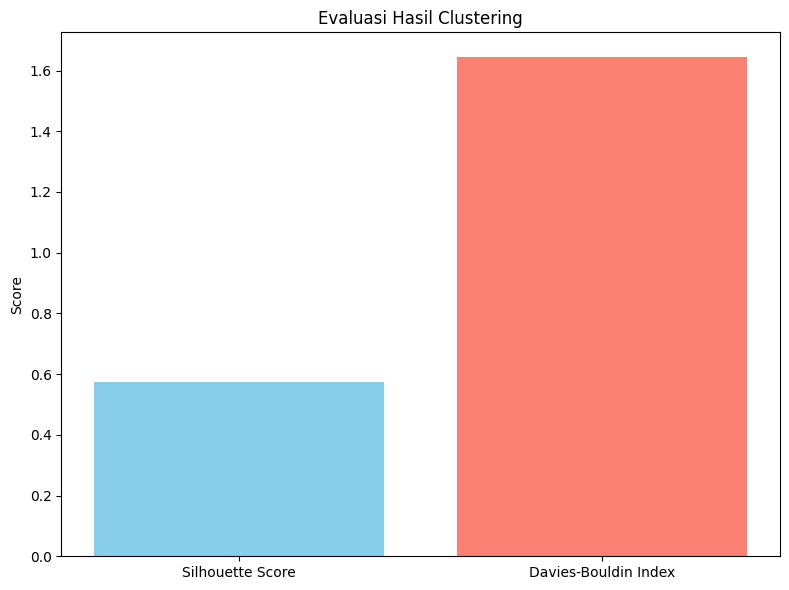

In [ ]:
scores = {
    "Silhouette Score": sil_score,
    "Davies-Bouldin Index": dbi_score
}

fig, ax = plt.subplots(figsize=(8, 6))
ax.bar(scores.keys(), scores.values(), color=['skyblue', 'salmon'])
ax.set_title("Evaluasi Hasil Clustering")
ax.set_ylabel("Score")
plt.tight_layout()
plt.show()

## TUGAS

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import hdbscan

from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [ ]:
digits = load_digits()
X = digits.data
y = digits.target

print("Shape data:", X.shape)
print("Jumlah kelas asli:", len(np.unique(y)))

Shape data: (1797, 64)
Jumlah kelas asli: 10


In [ ]:
hdb = hdbscan.HDBSCAN(min_cluster_size=15, min_samples=5)
labels = hdb.fit_predict(X)

n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print("Jumlah cluster terbentuk:", n_clusters_)
print("Jumlah noise:", n_noise_)

Jumlah cluster terbentuk: 13
Jumlah noise: 623


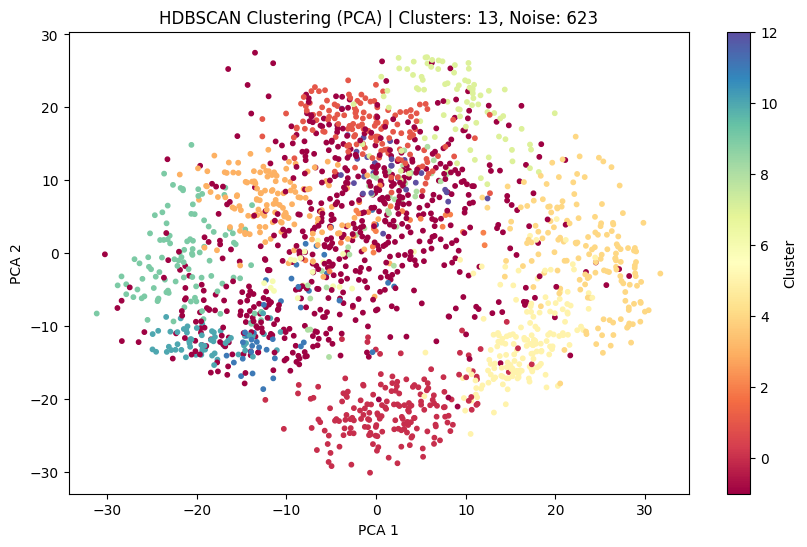

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(10, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='Spectral', s=10)
plt.title(f"HDBSCAN Clustering (PCA) | Clusters: {n_clusters_}, Noise: {n_noise_}")
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.colorbar(label='Cluster')
plt.show()

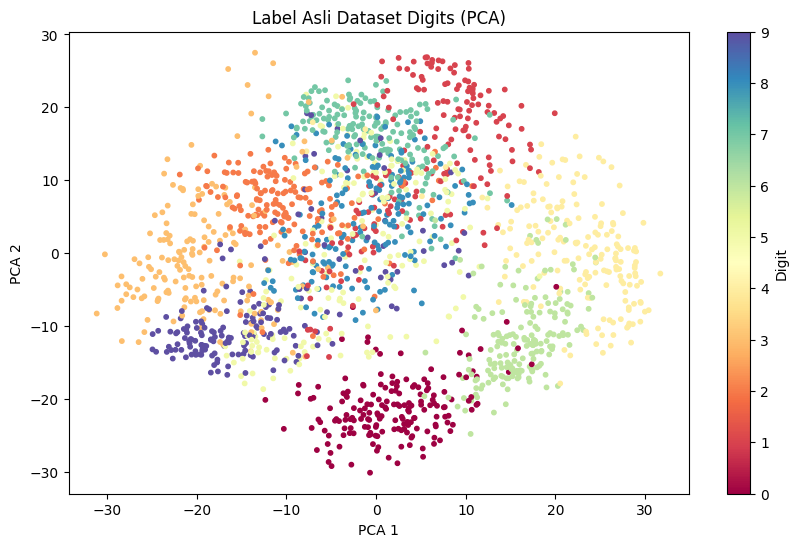

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='Spectral', s=10)
plt.title("Label Asli Dataset Digits (PCA)")
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.colorbar(label='Digit')
plt.show()

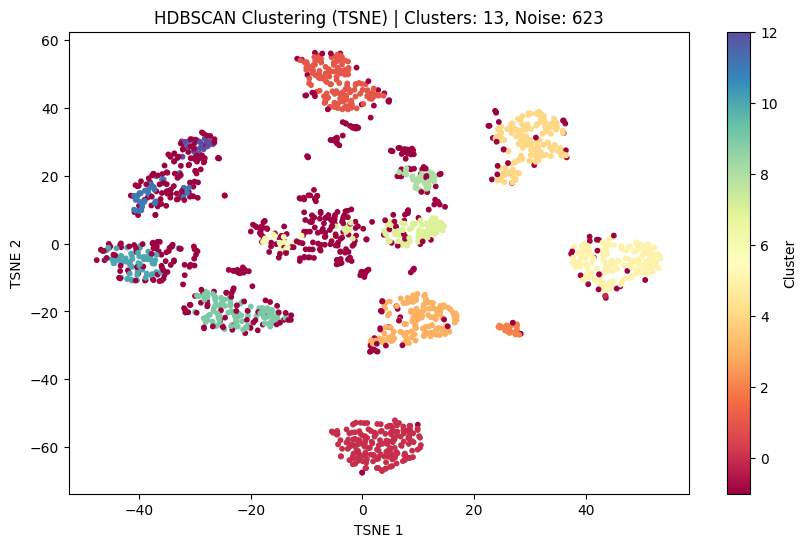

In [ ]:
tsne = TSNE(n_components=2, init='random', random_state=0)
X_tsne = tsne.fit_transform(X)

plt.figure(figsize=(10, 6))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=labels, cmap='Spectral', s=10)
plt.title(f"HDBSCAN Clustering (TSNE) | Clusters: {n_clusters_}, Noise: {n_noise_}")
plt.xlabel('TSNE 1')
plt.ylabel('TSNE 2')
plt.colorbar(label='Cluster')
plt.show()

In [ ]:
from sklearn.metrics import (
    homogeneity_score,
    completeness_score,
    v_measure_score,
    adjusted_rand_score,
    adjusted_mutual_info_score,
    silhouette_score,
)

print(f"Homogeneity: {homogeneity_score(y, labels):.3f}")
print(f"Completeness: {completeness_score(y, labels):.3f}")
print(f"V-measure: {v_measure_score(y, labels):.3f}")
print(f"Adjusted Rand Index: {adjusted_rand_score(y, labels):.3f}")
print(f"Adjusted Mutual Information: {adjusted_mutual_info_score(y, labels):.3f}")

# Silhouette dihitung pada data asli (bukan hasil reduksi)
if n_clusters_ > 1:
    print(f"Silhouette Coefficient: {silhouette_score(X, labels):.3f}")

Homogeneity: 0.690
Completeness: 0.728
V-measure: 0.708
Adjusted Rand Index: 0.405
Adjusted Mutual Information: 0.704
Silhouette Coefficient: 0.079


## Analisis Singkat

Berdasarkan hasil clustering HDBSCAN pada dataset digits:

1. **Jumlah cluster**: HDBSCAN membentuk sejumlah cluster yang cenderung lebih sedikit dari 10 kelas asli, karena beberapa digit memiliki bentuk tulisan yang mirip (misalnya 3 dan 8, atau 1 dan 7) sehingga sulit dipisahkan hanya berdasarkan densitas.

2. **Noise**: Terdapat sejumlah titik yang ditandai sebagai noise (-1). Ini adalah sampel digit dengan bentuk tulisan yang tidak umum atau berada di area berbatasan antar cluster.

3. **Kesesuaian dengan label asli**: Nilai Adjusted Rand Index (ARI) dan Adjusted Mutual Information (AMI) menunjukkan tingkat kesesuaian antara cluster HDBSCAN dengan label asli. Nilai yang moderat (bukan mendekati 1) mengindikasikan bahwa HDBSCAN tidak sepenuhnya memisahkan digit sesuai labelnya dan ini wajar karena HDBSCAN adalah metode unsupervised yang tidak tahu tentang label digit.

4. **Kesimpulan**: HDBSCAN dapat menemukan struktur kelompok alami dalam data digits, tetapi tidak selalu sejalan dengan label asli karena sifatnya yang berbasis densitas dan tidak memperhatikan makna semantik label. Visualisasi PCA/TSNE memperlihatkan bahwa beberapa kelompok terpisah dengan baik, namun ada area di mana cluster bercampur yang mencerminkan kemiripan antar digit yang berbeda.